# Chapter 19: Bayesian Inference and Conjugate Priors

The computational applications of this chapter of *Theory of Statistics*. The code is generated automatically from the book's `code/ch19/` files; see the book for the explanations and proofs.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ibrahimguney/statistical-theory/blob/main/notebooks/ch_19.ipynb)

$$
\newcommand{\R}{\mathbb{R}}\newcommand{\N}{\mathbb{N}}\newcommand{\E}{\mathbb{E}}
\newcommand{\P}{\mathbb{P}}\newcommand{\F}{\mathcal{F}}\newcommand{\I}{\mathbb{I}}
\newcommand{\Var}{\operatorname{Var}}\newcommand{\Cov}{\operatorname{Cov}}
\newcommand{\Corr}{\operatorname{Corr}}\newcommand{\MSE}{\operatorname{MSE}}
\newcommand{\Bias}{\operatorname{Bias}}\newcommand{\Normal}{\mathcal{N}}
\newcommand{\iid}{\overset{\text{i.i.d.}}{\sim}}\newcommand{\pto}{\xrightarrow{P}}
\newcommand{\dto}{\xrightarrow{d}}\newcommand{\X}{\mathbf{X}}\newcommand{\x}{\mathbf{x}}
$$

In [1]:
# Setup: numpy, scipy and matplotlib are preinstalled on Colab. Locally:
#   pip install -r code/requirements.txt
# Figure files (PDF) saved by the code are written to the _figures/ folder; the figures are
# also shown inside the notebook.
import os
os.makedirs("_figures", exist_ok=True)
os.chdir("_figures")
%matplotlib inline

## Beta–Binomial: Posterior Summaries and the HPD Interval

*Source file:* `code/ch19/c19_1_beta_binomial_posterior_summaries_hpd.py`

In [2]:
import scipy.stats as stats
import numpy as np
from scipy.optimize import minimize_scalar

a_post, b_post = 2 + 10, 18 + 40
print(f"Bayes estimate: {a_post / (a_post + b_post):.4f}")
print(f"Credible interval: {stats.beta.ppf([0.025, 0.975], a_post, b_post)}")

post = stats.beta(a_post, b_post)
print(f"Posterior median = {post.median():.4f} | mode (MAP) = {(a_post-1)/(a_post+b_post-2):.4f} | sd = {post.std():.4f}")
# HPD: the u minimising the length of [ppf(u), ppf(u+0.95)]
w = lambda u: post.ppf(u + 0.95) - post.ppf(u)
u = minimize_scalar(w, bounds=(0, 0.05), method="bounded").x
L, U = post.ppf(u), post.ppf(u + 0.95)
print(f"95% HPD = [{L:.4f}, {U:.4f}] (length {U-L:.4f}) | density at endpoints: {post.pdf(L):.3f}, {post.pdf(U):.3f}")
lo, hi = post.ppf([0.025, 0.975])
print(f"Equal-tailed length = {hi-lo:.4f}")
print(f"P(theta > 0.15 | x) = {post.sf(0.15):.4f}")

Bayes estimate: 0.1714
Credible interval: [0.09322494 0.2673681 ]
Posterior median = 0.1683 | mode (MAP) = 0.1618 | sd = 0.0447
95% HPD = [0.0879, 0.2603] (length 0.1724) | density at endpoints: 1.352, 1.352
Equal-tailed length = 0.1741
P(theta > 0.15 | x) = 0.6631


## Prior, Likelihood and Posterior; Bernstein–von Mises

*Source file:* `code/ch19/c19_2_prior_likelihood_posterior_bvm.py`

n=   20 | posterior mean=0.1750 | MLE=0.2500 | TV(posterior, BvM normal)=0.4203
n=  200 | posterior mean=0.2091 | MLE=0.2200 | TV(posterior, BvM normal)=0.1658
n= 2000 | posterior mean=0.2178 | MLE=0.2190 | TV(posterior, BvM normal)=0.0550


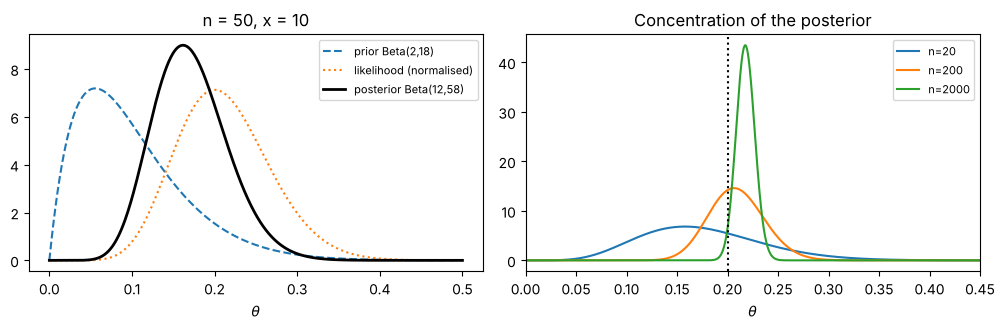

In [3]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

t = np.linspace(0, 0.5, 600)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
prior = stats.beta(2, 18)
ax[0].plot(t, prior.pdf(t), "--", label="prior Beta(2,18)")
ax[0].plot(t, stats.beta(11, 41).pdf(t), ":", label="likelihood (normalised)")
ax[0].plot(t, stats.beta(12, 58).pdf(t), "k", lw=2, label="posterior Beta(12,58)")
ax[0].set_xlabel(r"$\theta$"); ax[0].legend(fontsize=8); ax[0].set_title("n = 50, x = 10")

rng = np.random.default_rng(42)
theta0 = 0.2
for n in [20, 200, 2000]:
    x = rng.binomial(n, theta0)
    ps = stats.beta(2 + x, 18 + n - x)
    mle = x / n
    bvm = stats.norm(mle, np.sqrt(mle*(1-mle)/n))
    tt = np.linspace(0, 0.5, 2000)
    tv = 0.5*np.sum(np.abs(ps.pdf(tt) - bvm.pdf(tt))) * (tt[1] - tt[0])
    ax[1].plot(tt, ps.pdf(tt), label=f"n={n}")
    print(f"n={n:5d} | posterior mean={ps.mean():.4f} | MLE={mle:.4f} | TV(posterior, BvM normal)={tv:.4f}")
ax[1].axvline(theta0, color="k", ls=":"); ax[1].set_xlim(0, 0.45); ax[1].legend(fontsize=8)
ax[1].set_xlabel(r"$\theta$"); ax[1].set_title("Concentration of the posterior")
fig.tight_layout(); fig.savefig("bayes_sonsal.pdf")

## Frequentist Coverage of Bayesian Intervals

*Source file:* `code/ch19/c19_3_frequentist_coverage_bayesian_intervals.py`

In [4]:
import numpy as np
from scipy import stats

def coverage_jeffreys(n, ps, a=0.05):
    x = np.arange(n + 1)
    L = np.where(x > 0, stats.beta.ppf(a/2, x + 0.5, n - x + 0.5), 0.0)
    U = np.where(x < n, stats.beta.ppf(1 - a/2, x + 0.5, n - x + 0.5), 1.0)
    return np.array([np.sum(stats.binom.pmf(x, n, p) * ((L <= p) & (p <= U))) for p in ps])

ps = np.linspace(0.005, 0.995, 991)
for n in [30, 100]:
    k = coverage_jeffreys(n, ps)
    print(f"n={n:3d} | Jeffreys interval: mean coverage={k.mean():.4f}, min={k.min():.4f}")

n= 30 | Jeffreys interval: mean coverage=0.9505, min=0.8887
n=100 | Jeffreys interval: mean coverage=0.9498, min=0.8806


## A Non-Conjugate Model: The Metropolis Algorithm

The algorithm goes back to Metropolis and co-authors . If a $\Normal(0,1.5^2)$ prior is placed on the logit parameter $\eta=\ln\frac{\theta}{1-\theta}$, the posterior is not in closed form. The random-walk Metropolis algorithm: from the current $\eta$, propose $\eta'=\eta+\varepsilon$, $\varepsilon\sim\Normal(0,s^2)$; accept with probability $\min\{1,\pi(\eta'\mid x)/\pi(\eta\mid x)\}$. The stationary distribution of this chain is the posterior; the normalising constant $m(x)$ is never needed.

*Source file:* `code/ch19/c19_4_nonconjugate_model_metropolis.py`

In [5]:
import numpy as np
from scipy import stats, integrate

rng = np.random.default_rng(42)
x, n, s0 = 10, 50, 1.5
def log_post(eta):        # log-likelihood + log-prior (up to constants)
    return x*eta - n*np.log1p(np.exp(eta)) - eta**2 / (2*s0**2)

N, s = 60_000, 0.6
chain = np.empty(N); eta = 0.0; lp = log_post(eta); acc = 0
for i in range(N):
    prop = eta + s*rng.standard_normal()
    lp_prop = log_post(prop)
    if np.log(rng.random()) < lp_prop - lp:
        eta, lp = prop, lp_prop; acc += 1
    chain[i] = eta
theta = 1/(1 + np.exp(-chain[5_000:]))          # discard burn-in

# Check: exact posterior mean by numerical integration
Z = integrate.quad(lambda e: np.exp(log_post(e)), -10, 10)[0]
m_exact = integrate.quad(lambda e: np.exp(log_post(e))/(1 + np.exp(-e)), -10, 10)[0] / Z
print(f"Acceptance rate = {acc/N:.3f}")
print(f"MCMC  posterior mean E[theta|x] = {theta.mean():.4f} | 95% interval = {np.percentile(theta, [2.5, 97.5]).round(4)}")
print(f"Exact posterior mean (quad)      = {m_exact:.4f}")
print(f"Comparison: Beta(2,18) conjugate posterior mean = {12/70:.4f} | MLE = {x/n:.4f}")

Acceptance rate = 0.538
MCMC  posterior mean E[theta|x] = 0.2115 | 95% interval = [0.1126 0.3318]
Exact posterior mean (quad)      = 0.2119
Comparison: Beta(2,18) conjugate posterior mean = 0.1714 | MLE = 0.2000


## Empirical Bayes: James–Stein and Robbins' Formula

The first part compares the average loss, that is, the Bayes risk, of four estimators in the hierarchical normal model ($k=10$): $\X$; James–Stein shrinking towards zero; Efron–Morris (EM) shrinking towards the data's mean; and the oracle Bayes rule that knows $\mu$ and $\tau^2$. The theoretical values are taken from Theorem 19.18 and Exercise 19.5. The second part compares, in $N=2000$ units with $\theta_i\sim\text{Gamma}(2,1)$ and $X_i\mid\theta_i\sim\text{Poisson}(\theta_i)$, the Robbins estimate (Proposition 19.20) with the true posterior mean $(2+x)/2$ known from Gamma–Poisson conjugacy.

*Source file:* `code/ch19/c19_5_empirical_bayes_james_stein_robbins.py`

In [6]:
import numpy as np

rng = np.random.default_rng(42)

# 1) Hierarchical normal model: theta_i ~ N(mu, tau^2), X_i | theta_i ~ N(theta_i, 1), i = 1..k.
#    Average total loss (Bayes risk): X, JS shrinking to 0, Efron--Morris shrinking to the mean, oracle Bayes
k, R = 10, 100_000
for mu, tau2 in [(0.0, 0.5), (0.0, 2.0), (0.0, 8.0), (3.0, 2.0)]:
    theta = mu + np.sqrt(tau2) * rng.normal(size=(R, k))
    X = theta + rng.normal(size=(R, k))
    B = 1 / (1 + tau2)
    js = (1 - (k - 2) / np.sum(X**2, axis=1, keepdims=True)) * X
    xbar = X.mean(axis=1, keepdims=True)
    S = np.sum((X - xbar)**2, axis=1, keepdims=True)
    em = xbar + (1 - (k - 3) / S) * (X - xbar)
    bayes = mu + (1 - B) * (X - mu)                        # oracle that knows mu and tau^2
    loss = lambda d: np.mean(np.sum((d - theta)**2, axis=1))
    js_theory = f"{k-(k-2)*B:6.3f}" if mu == 0 else "   -  "     # formula only for mu = 0
    print(f"mu={mu:.0f}, tau^2={tau2:3.1f} | X={loss(X):6.3f} | JS={loss(js):6.3f}"
          f" (theory {js_theory}) | EM={loss(em):6.3f} (theory {k-(k-3)*B:6.3f})"
          f" | oracle={loss(bayes):6.3f} (theory {k*(1-B):6.3f})")

# 2) Robbins' formula: theta_i ~ Gamma(shape 2, rate 1), X_i | theta_i ~ Poisson(theta_i), N units.
#    True posterior mean (Gamma--Poisson): (2 + x) / 2
N = 2000
theta = rng.gamma(2.0, 1.0, size=N)
X = rng.poisson(theta)
counts = np.bincount(X, minlength=12)
print(" x | count | Robbins (x+1)N(x+1)/N(x) | true Bayes | MLE")
for x in range(8):
    robbins = (x + 1) * counts[x + 1] / counts[x]
    print(f"{x:2d} | {counts[x]:5d} | {robbins:24.3f} | {(2 + x) / 2:10.3f} | {x:3d}")
# mean squared error over the units with x <= 7 (most of the data)
s = X <= 7
rob = np.array([(x + 1) * counts[x + 1] / counts[x] for x in range(8)])[X[s]]
err = lambda d: np.mean((d - theta[s])**2)
print(f"Mean squared error over the {s.sum()} units with x<=7: MLE={err(X[s]):.3f} | Robbins={err(rob):.3f}"
      f" | true Bayes={err((2 + X[s]) / 2):.3f}")

mu=0, tau^2=0.5 | X= 9.985 | JS= 4.663 (theory  4.667) | EM= 5.339 (theory  5.333) | oracle= 3.332 (theory  3.333)
mu=0, tau^2=2.0 | X=10.003 | JS= 7.330 (theory  7.333) | EM= 7.667 (theory  7.667) | oracle= 6.661 (theory  6.667)


mu=0, tau^2=8.0 | X=10.008 | JS= 9.116 (theory  9.111) | EM= 9.227 (theory  9.222) | oracle= 8.888 (theory  8.889)


mu=3, tau^2=2.0 | X= 9.994 | JS= 9.413 (theory    -  ) | EM= 7.661 (theory  7.667) | oracle= 6.662 (theory  6.667)
 x | count | Robbins (x+1)N(x+1)/N(x) | true Bayes | MLE
 0 |   499 |                    0.988 |      1.000 |   0
 1 |   493 |                    1.639 |      1.500 |   1
 2 |   404 |                    1.723 |      2.000 |   2
 3 |   232 |                    2.759 |      2.500 |   3
 4 |   160 |                    2.656 |      3.000 |   4
 5 |    85 |                    3.671 |      3.500 |   5
 6 |    52 |                    3.904 |      4.000 |   6
 7 |    29 |                    4.966 |      4.500 |   7
Mean squared error over the 1954 units with x<=7: MLE=1.628 | Robbins=0.959 | true Bayes=0.920
